In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('weight-height.csv')

In [2]:
df.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


In [3]:
df.shape

(10000, 3)

In [4]:
df.describe()

,Height,Weight
count,10000.000000,10000.000000
mean,66.367560,161.440357
std,3.847528,32.108439
min,54.263133,64.700127
25%,63.505620,135.818051
50%,66.318070,161.212928
75%,69.174262,187.169525
max,78.998742,269.989699


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Gender  10000 non-null  object 
 1   Height  10000 non-null  float64
 2   Weight  10000 non-null  float64
dtypes: float64(2), object(1)
memory usage: 234.5+ KB


In [6]:
df.isnull().sum()

,0
Gender,0
Height,0
Weight,0


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [8]:

data = pd.DataFrame(df)
print(data)

      Gender     Height      Weight
0       Male  73.847017  241.893563
1       Male  68.781904  162.310473
2       Male  74.110105  212.740856
3       Male  71.730978  220.042470
4       Male  69.881796  206.349801
...      ...        ...         ...
9995  Female  66.172652  136.777454
9996  Female  67.067155  170.867906
9997  Female  63.867992  128.475319
9998  Female  69.034243  163.852461
9999  Female  61.944246  113.649103

[10000 rows x 3 columns]


In [9]:
print("Dataset Information")
print("Number of observations:", len(data))
print("Number of features:", len(data.columns))

Dataset Information
Number of observations: 10000
Number of features: 3


In [10]:
#Independent Variable
X = data[['Height']]

#Depndent Variable
Y = data['Weight']

print("Independent Variable (X):")
print(X)

print("\nDependent Variable (Y):")
print(Y)

Independent Variable (X):
         Height
0     73.847017
1     68.781904
2     74.110105
3     71.730978
4     69.881796
...         ...
9995  66.172652
9996  67.067155
9997  63.867992
9998  69.034243
9999  61.944246

[10000 rows x 1 columns]

Dependent Variable (Y):
0       241.893563
1       162.310473
2       212.740856
3       220.042470
4       206.349801
           ...    
9995    136.777454
9996    170.867906
9997    128.475319
9998    163.852461
9999    113.649103
Name: Weight, Length: 10000, dtype: float64


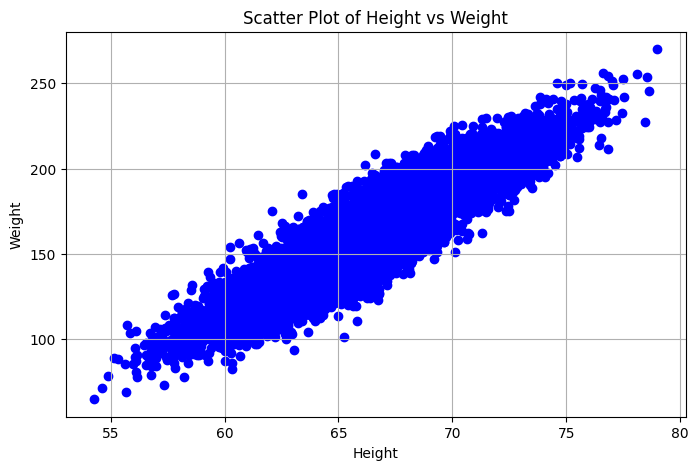

In [11]:
#sactter plot
plt.figure(figsize=(8,5))
plt.scatter(X, Y, color='Blue')
plt.title('Scatter Plot of Height vs Weight')
plt.xlabel('Height')
plt.ylabel('Weight')
plt.grid(True)
plt.show()

In [12]:
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
print("Training Sample:",len(x_train))
print("Testing Sample:",len(x_test))

Training Sample: 8000
Testing Sample: 2000


In [13]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [14]:
#1.SIMPLE LINEAR REGRESSION
lr_model = LinearRegression()
lr_model.fit(x_train_scaled, y_train)
lr_predictions = lr_model.predict(x_test_scaled)
print("Intercept:", lr_model.intercept_)
print("Coefficients:", lr_model.coef_)
print("Regression Equation:", "Weight = ", lr_model.intercept_, "+", lr_model.coef_[0], "* Height")

Intercept: 161.3267623130613
Coefficients: [29.61903439]
Regression Equation: Weight =  161.3267623130613 + 29.619034394403037 * Height


In [15]:
#2.RIDGE REGRESSION
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(x_train_scaled, y_train)
ridge_predictions = ridge_model.predict(x_test_scaled)
print("RIDGE REGRESSION")
print("=" * 50)
print("Alpha:",ridge_model.alpha)
print("Intercept:", ridge_model.intercept_)
print("Coefficients:", ridge_model.coef_)
print("Regression Equation:", "Weight = ", ridge_model.intercept_, "+", ridge_model.coef_[0], "* Height")

RIDGE REGRESSION
Alpha: 1.0
Intercept: 161.3267623130613
Coefficients: [29.61533248]
Regression Equation: Weight =  161.3267623130613 + 29.6153324778433 * Height


In [16]:
#3.LASSO REGRESSION
lasso_model = Lasso(alpha=1.0)
lasso_model.fit(x_train_scaled, y_train)
lasso_predictions = lasso_model.predict(x_test_scaled)
print("LASSO REGRESSION")
print("=" * 5)
print("Alpha:",lasso_model.alpha)
print("Intercept:", lasso_model.intercept_)
print("Coefficients:", lasso_model.coef_)
print("Regression Equation:", "Weight = ", lasso_model.intercept_, "+", lasso_model.coef_[0], "* Height")

LASSO REGRESSION
=====
Alpha: 1.0
Intercept: 161.3267623130613
Coefficients: [28.61903439]
Regression Equation: Weight =  161.3267623130613 + 28.619034394403045 * Height


In [17]:

# 4. DECISION TREE

from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(x_train_scaled, y_train)

dt_predictions = dt_model.predict(x_test_scaled)

print("DECISION TREE")
print("=" * 50)
print("Depth:",dt_model.get_depth())

DECISION TREE
Depth: 58


In [18]:
#5. RANDOM FOREST REGRESSION
from sklearn.ensemble import RandomForestRegressor
forest_model = RandomForestRegressor(n_estimators=100, random_state=42)
forest_model.fit(x_train_scaled, y_train)
forest_predictions = forest_model.predict(x_test_scaled)
print("RANDOM FOREST REGRESSION")
print("=" * 50)
print("Number of Estimators:",forest_model.n_estimators)
print("Maximum Depth:",forest_model.max_depth)

RANDOM FOREST REGRESSION
Number of Estimators: 100
Maximum Depth: None


In [19]:
prediction = {
    'Linear Regression': lr_predictions,
    'Ridge Regression': ridge_predictions,
    'Lasso Regression': lasso_predictions,
    'Decision Tree': dt_predictions,
    'Random Forest': forest_predictions
}

In [20]:
results = []

for model_name, predictions in prediction.items():
    mse = mean_squared_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)
    results.append((model_name, mse, r2))

results_df = pd.DataFrame(results, columns=['Model', 'Mean Squared Error', 'R-squared'])
print(results_df)

               Model  Mean Squared Error  R-squared
0  Linear Regression          149.003504   0.857732
1   Ridge Regression          149.005674   0.857730
2   Lasso Regression          150.590587   0.856216
3      Decision Tree          279.795200   0.732852
4      Random Forest          204.942075   0.804322


In [21]:
print(results_df.round(4).to_string(index=False))

            Model  Mean Squared Error  R-squared
Linear Regression            149.0035     0.8577
 Ridge Regression            149.0057     0.8577
 Lasso Regression            150.5906     0.8562
    Decision Tree            279.7952     0.7329
    Random Forest            204.9421     0.8043


In [22]:
comparison_df = pd.DataFrame({
    'Actual Weight': y_test,
    'Linear Regression': lr_predictions,
    'Ridge Regression': ridge_predictions,
    'Lasso Regression': lasso_predictions,
    'Decision Tree': dt_predictions,
    'Random Forest': forest_predictions
})
print(comparison_df)

      Actual Weight  Linear Regression  Ridge Regression  Lasso Regression  \
6252     173.115813         179.253990        179.251750        178.648730   
4684     195.162042         180.348483        180.346106        179.706270   
1731     170.217451         161.622888        161.622851        161.612890   
4742     215.049660         204.225307        204.219946        202.776963   
4521     182.721452         166.589062        166.588404        166.411396   
...             ...                ...               ...               ...   
6412     142.067438         156.620109        156.620697        156.779015   
8285     119.967881         117.980213        117.985631        119.443682   
7853     125.179380         129.202882        129.206897        130.287451   
1095     187.573494         166.784705        166.784023        166.600434   
6929     102.469087         101.812275        101.819713        103.821607   

      Decision Tree  Random Forest  
6252     203.560334     18

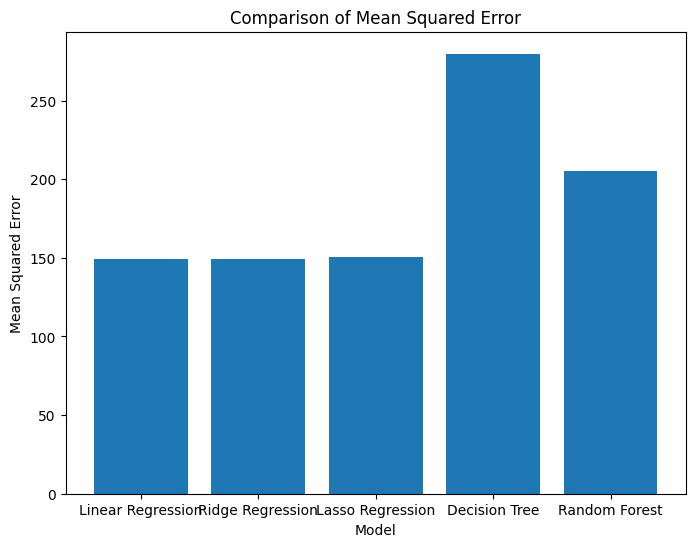

In [23]:
#bar plot
plt.figure(figsize=(8, 6))
plt.bar(results_df['Model'], results_df['Mean Squared Error'])
plt.xlabel('Model')
plt.ylabel('Mean Squared Error')
plt.title('Comparison of Mean Squared Error')
plt.show()

In [24]:
x_range = np.linspace(min(x_test['Height']), max(x_test['Height']), 100).reshape(-1, 1)
x_range

array([[55.73973682],
       [55.96555632],
       [56.19137582],
       [56.41719532],
       [56.64301483],
       [56.86883433],
       [57.09465383],
       [57.32047333],
       [57.54629283],
       [57.77211233],
       [57.99793184],
       [58.22375134],
       [58.44957084],
       [58.67539034],
       [58.90120984],
       [59.12702934],
       [59.35284884],
       [59.57866835],
       [59.80448785],
       [60.03030735],
       [60.25612685],
       [60.48194635],
       [60.70776585],
       [60.93358536],
       [61.15940486],
       [61.38522436],
       [61.61104386],
       [61.83686336],
       [62.06268286],
       [62.28850236],
       [62.51432187],
       [62.74014137],
       [62.96596087],
       [63.19178037],
       [63.41759987],
       [63.64341937],
       [63.86923888],
       [64.09505838],
       [64.32087788],
       [64.54669738],
       [64.77251688],
       [64.99833638],
       [65.22415588],
       [65.44997539],
       [65.67579489],
       [65

In [25]:
#Prediction for smooth curves
linear_curve = lr_model.predict(x_range)
ridge_curve = ridge_model.predict(scaler.transform(x_range))
lasso_curve = lasso_model.predict(scaler.transform(x_range))
dt_curve = dt_model.predict(x_range)
forest_curve = forest_model.predict(x_range)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


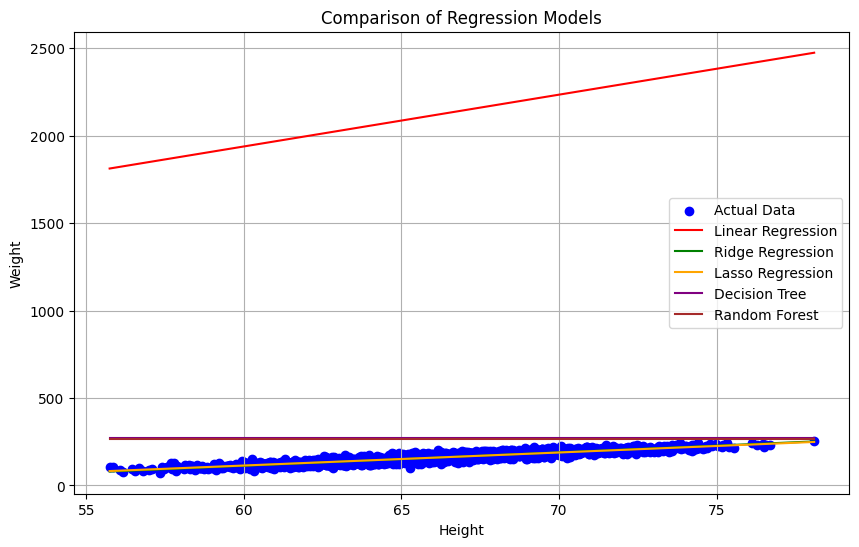

In [26]:
#plot for all regression
plt.figure(figsize=(10, 6))
plt.scatter(x_test['Height'], y_test, color='blue', label='Actual Data')
plt.plot(x_range, linear_curve, color='red', label='Linear Regression')
plt.plot(x_range, ridge_curve, color='green', label='Ridge Regression')
plt.plot(x_range, lasso_curve, color='orange', label='Lasso Regression')
plt.plot(x_range, dt_curve, color='purple', label='Decision Tree')
plt.plot(x_range, forest_curve, color='brown', label='Random Forest')
plt.xlabel('Height')
plt.ylabel('Weight')
plt.title('Comparison of Regression Models')
plt.legend()
plt.grid(True)
plt.show()

In [27]:


new_height = [[12]]
new_linear = lr_model.predict(new_height)[0]
new_ridge = ridge_model.predict(scaler.transform(new_height))[0]
new_lasso = lasso_model.predict(scaler.transform(new_height))[0]
new_dt = dt_model.predict(new_height)[0]
new_forest = forest_model.predict(new_height)[0]
prediction_result = pd.DataFrame({
    "model" : ["Linear Regression", "Ridge Regression", "Lasso Regression", "Decision Tree", "Random Forest"],
    "prediction" : [new_linear, new_ridge, new_lasso, new_dt, new_forest]
})
print(prediction_result)

               model  prediction
0  Linear Regression  516.755175
1   Ridge Regression -257.309264
2   Lasso Regression -243.225807
3      Decision Tree  269.989699
4      Random Forest  262.980214


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [28]:
models = {
    'Linear Regression': lr_model,
    'Ridge Regression': ridge_model,
    'Lasso Regression': lasso_model,
    'Decision Tree': dt_model,
    'Random Forest': forest_model
}

In [29]:



best_model = results_df.loc[results_df['R-squared'].idxmax(), 'Model']
best_model

'Linear Regression'

In [30]:
import joblib
joblib.dump(best_model, "best_model.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

In [31]:
model = joblib.load("best_model.pkl")
scaler = joblib.load("scaler.pkl")

In [32]:
def predict_weight(weight):
  sample_weight = np.array([[weight]])
  sample_weight_scaled = scaler.transform(sample_weight)
  predicted_weight = model.predict(sample_weight_scaled)
  return predicted_weight[0]